# Extensions

Seven extensions to the results in `notebooks/Results.ipynb`. The data
come from `python -m utils.extensions` (see the docstring of
`utils/extensions.py`):

| File | Extension |
|---|---|
| `data/ext_fine_sweep.csv`, `data/ext_wait_samples.npz` | 1 tipping point, 2 self-organised timing, 3 distributions: arrival rate 0.02 to 0.30 in steps of 0.01, north-south probability 0.5 and 0.9, right-turn probability 0.3, reaction delay 0 and 0.2, 10 seeds, all three controllers |
| `data/ext_sensing.csv` | 4 limited sensing |
| `data/ext_drivers.csv` | 5 different drivers |
| `data/ext_surge.npz` | 6 time-varying demand |
| `data/ext_overload.csv`, `data/fine_sweeps_queued.csv` | 7 overload: blocked cars queue instead of being turned away |

Figures are saved to `figures/` with names starting `ext_`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path("../..")
FIGURES = ROOT / "figures"
FIGURES.mkdir(exist_ok=True)                  # figures are not stored in the repository

CONTROLLERS = ["fixed", "webster", "adaptive"]
LABELS = {"fixed": "Fixed-time (untuned)", "webster": "Fixed-time (Webster)", "adaptive": "Adaptive"}
COLOURS = {"fixed": "C0", "webster": "C2", "adaptive": "C1"}
# A second colour for each controller, for a second condition shown in the same
# panel (such as reaction delay 0.2, or blocked cars turned away).
ALT_COLOURS = {"fixed": "C4", "webster": "C5", "adaptive": "C3"}

fine = pd.read_csv(ROOT / "data" / "ext_fine_sweep.csv")
fine["turned_away"] = fine["blocked_arrivals"] / (400 * fine["arrival_rate"])
fine["ns_green_fraction"] = (fine["green_fraction_1"] + fine["green_fraction_2"]) / fine[
    ["green_fraction_1", "green_fraction_2", "green_fraction_3", "green_fraction_4"]].sum(axis=1)
fine["design_ns_fraction"] = (fine["design_fraction_1"] + fine["design_fraction_2"]) / fine[
    ["design_fraction_1", "design_fraction_2", "design_fraction_3", "design_fraction_4"]].sum(axis=1)
fine["all_red_fraction"] = 1 - fine[["green_fraction_1", "green_fraction_2", "green_fraction_3", "green_fraction_4"]].sum(axis=1)
SETTINGS = ["controller", "north_south_probability", "reaction_delay", "arrival_rate"]
means = fine.groupby(SETTINGS).mean(numeric_only=True).reset_index()
print(len(fine), "runs in the fine sweep")


def lines(ax, value, p_ns):
    # One line per controller and reaction delay (0 in COLOURS, 0.2 in ALT_COLOURS), averaged over seeds.
    for controller in CONTROLLERS:
        for delay, colours in [(0.0, COLOURS), (0.2, ALT_COLOURS)]:
            data = means[(means["controller"] == controller) & (means["north_south_probability"] == p_ns)
                         & (means["reaction_delay"] == delay)]
            ax.plot(data["arrival_rate"], data[value], color=colours[controller],
                    label=f"{LABELS[controller]}, delay {delay}")

3480 runs in the fine sweep


## 1. Tipping point

As the arrival rate rises past what a controller can serve, the intersection
changes abruptly from free-flowing (short queues that clear every cycle) to
congested (queues filling the approaches). Three signs of such a transition
are measured in every run:

* the **mean number of cars on the approaches**, which jumps at the transition;
* **fluctuations**: the standard deviation of that number over the measured
  window, which peaks near the transition, because queues neither clear
  reliably nor stay full;
* **critical slowing down**: the settling time, the number of steps from an
  empty start until the number of cars first reaches 90% of its level in the
  measured window, which is longest near the transition.

The critical arrival rate of each controller is taken as the rate at which
the fluctuations peak. Each controller has one colour without reaction delay
and another with delay 0.2 (see the legend).

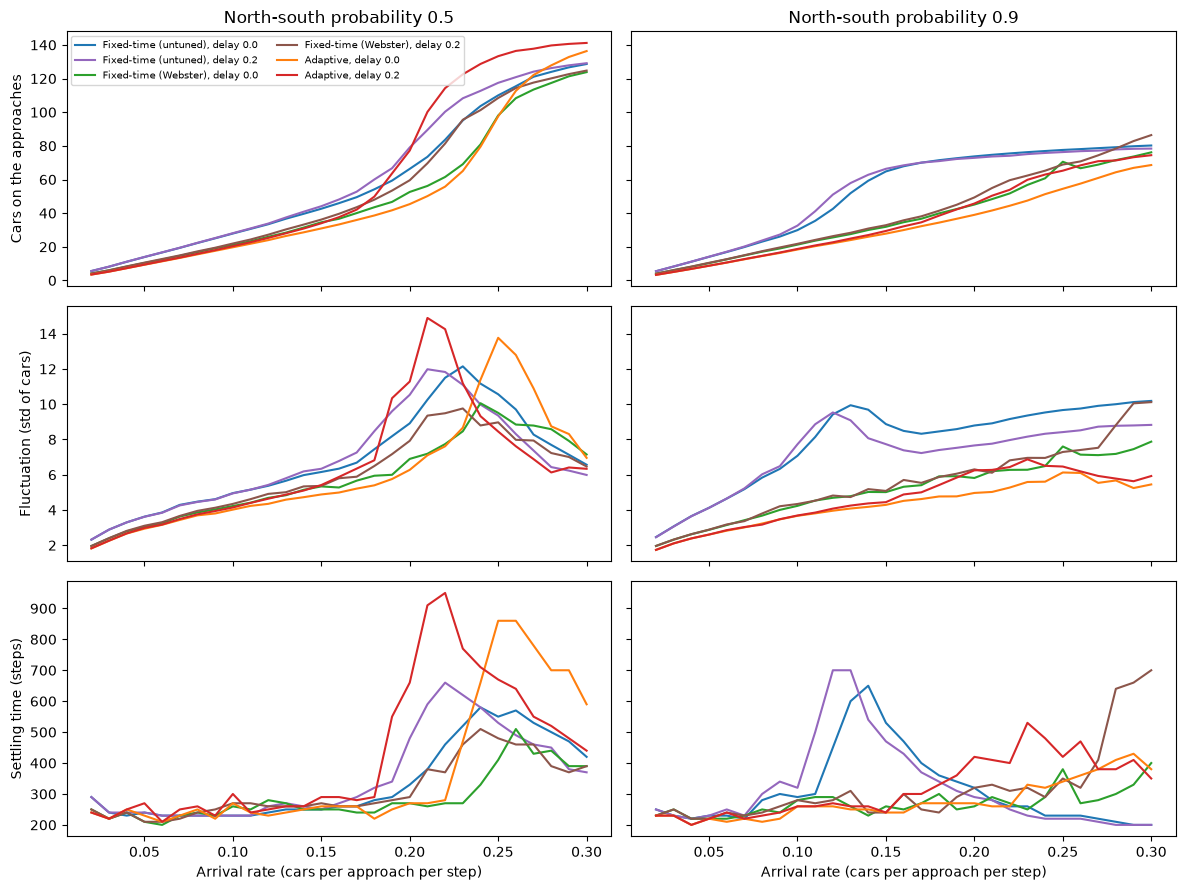

Critical arrival rate (where fluctuations peak; NaN = no peak within the sweep)
controller                              fixed  webster  adaptive
north_south_probability reaction_delay                          
0.5                     0.0              0.23     0.24      0.25
                        0.2              0.21     0.23      0.21
0.9                     0.0               NaN      NaN      0.25
                        0.2              0.12      NaN      0.23


In [2]:
ns_values = sorted(fine["north_south_probability"].unique())
rows = [("cars_mean", "Cars on the approaches"), ("cars_std", "Fluctuation (std of cars)"),
        ("settling_time", "Settling time (steps)")]
fig, axes = plt.subplots(len(rows), len(ns_values), figsize=(12, 9), sharex=True, sharey="row")
for col, p_ns in enumerate(ns_values):
    for row, (value, label) in enumerate(rows):
        lines(axes[row, col], value, p_ns)
        axes[row, 0].set_ylabel(label)
    axes[0, col].set_title(f"North-south probability {p_ns}")
    axes[-1, col].set_xlabel("Arrival rate (cars per approach per step)")
axes[0, 0].legend(fontsize=7, ncol=2)
fig.tight_layout()
plt.show()

peaks = means.loc[means.groupby(["controller", "north_south_probability", "reaction_delay"])["cars_std"].idxmax()]
peaks = peaks.set_index(["controller", "north_south_probability", "reaction_delay"])["arrival_rate"]
critical = peaks.where(peaks < means["arrival_rate"].max()).unstack("controller")   # a peak at the edge is no peak
print("Critical arrival rate (where fluctuations peak; NaN = no peak within the sweep)")
print(critical[CONTROLLERS])

The balanced case on its own, in one row (as used in the report).


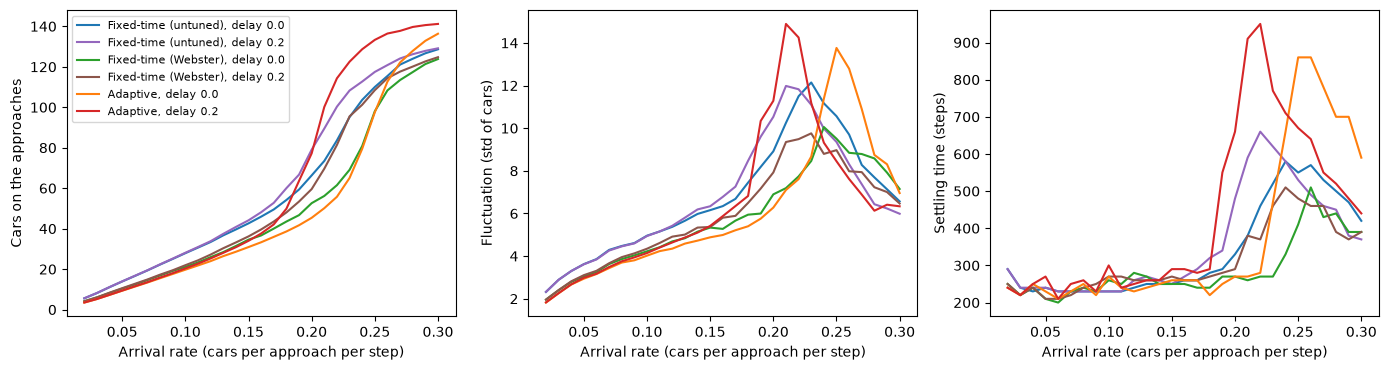

In [3]:
rows = [("cars_mean", "Cars on the approaches"), ("cars_std", "Fluctuation (std of cars)"),
        ("settling_time", "Settling time (steps)")]
fig, axes = plt.subplots(1, len(rows), figsize=(14, 3.8))
for ax, (value, label) in zip(axes, rows):
    lines(ax, value, 0.5)
    ax.set_ylabel(label)
    ax.set_xlabel("Arrival rate (cars per approach per step)")
axes[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "ext_tipping_balanced.png", dpi=200)
plt.show()

## 2. Self-organised timing

Webster's method designs a cycle length and a split of green time from the
average demand. The adaptive controller has no plan: the length of its greens,
how the green time is split between directions and the time between two
greens of the same phase (its effective cycle) all emerge from the waiting
cars. Does local feedback find the designed timing by itself?

Left: average length of a green. Middle: north-south fraction of the green
time. Right: fraction of time spent in all-red, the time lost to switching.
Top row: north-south probability 0.5; bottom row: 0.9. Each controller has one
colour without reaction delay and another with delay 0.2 (the untuned plan's
all-red time does not depend on the delay, so it is shown once).

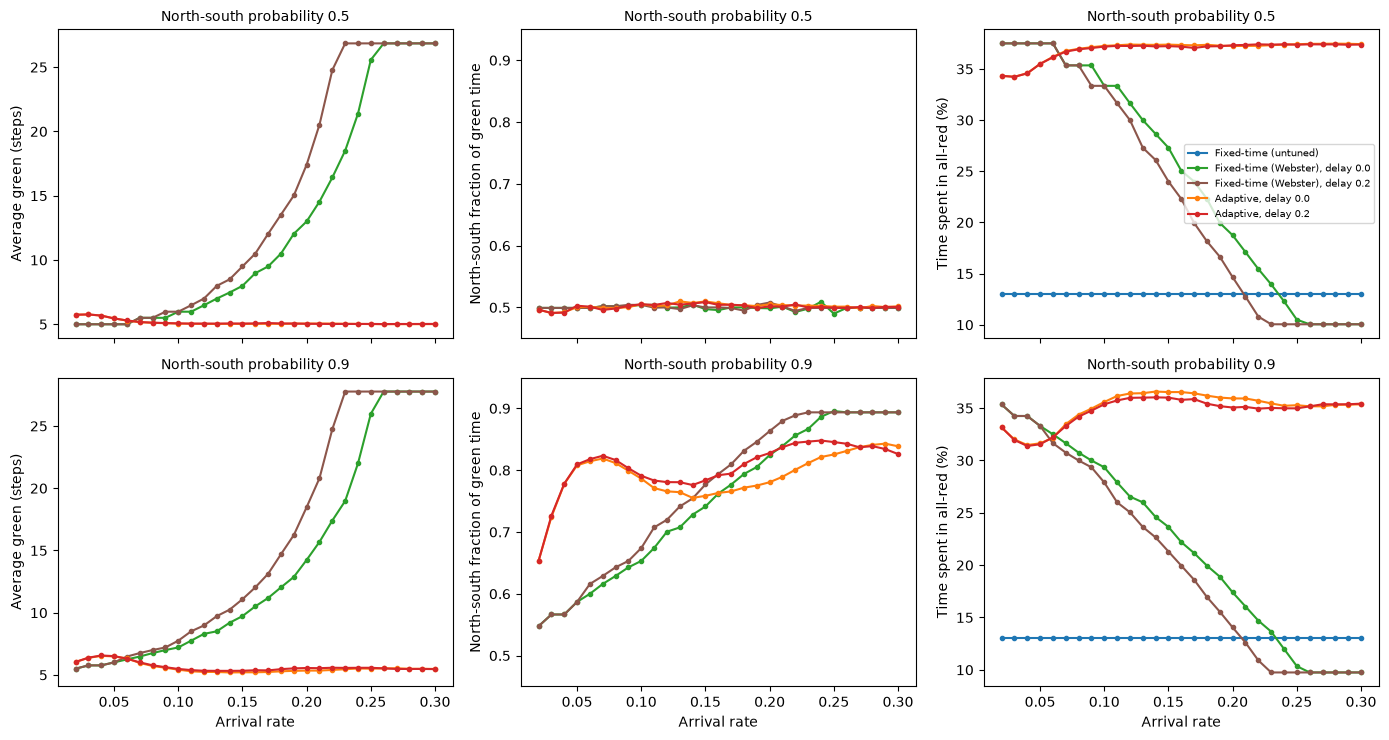

                                     mean_green            cycle design_cycle  \
controller                             adaptive webster adaptive      webster   
north_south_probability arrival_rate                                            
0.5                     0.05               5.46    5.00    35.22         32.0   
                        0.10               5.05    5.98    33.50         36.0   
                        0.15               5.03    7.99    33.34         44.0   
                        0.20               5.05   13.00    33.76         64.0   
                        0.25               5.01   25.57    34.15        114.0   
0.9                     0.05               6.49    6.01    61.01         36.0   
                        0.10               5.42    7.21    50.31         41.0   
                        0.15               5.21    9.73    45.56         51.0   
                        0.20               5.35   14.24    48.16         69.0   
                        0.25

In [4]:
means["mean_green"] = 100 * (1 - means["all_red_fraction"]) / means["phase_changes"]
ns_values = sorted(fine["north_south_probability"].unique())
panels = [("mean_green", "Average green (steps)", 1, ["webster", "adaptive"]),
          ("ns_green_fraction", "North-south fraction of green time", 1, ["webster", "adaptive"]),
          ("all_red_fraction", "Time spent in all-red (%)", 100, CONTROLLERS)]
fig, axes = plt.subplots(len(ns_values), len(panels), figsize=(14, 7.5), sharex=True)
for row, p_ns in enumerate(ns_values):
    for ax, (value, label, scale, controllers) in zip(axes[row], panels):
        for controller in controllers:
            delays = [(0.0, COLOURS)] if controller == "fixed" else [(0.0, COLOURS), (0.2, ALT_COLOURS)]
            for delay, colours in delays:
                runs = means[(means["controller"] == controller) & (means["north_south_probability"] == p_ns)
                             & (means["reaction_delay"] == delay)]
                name = LABELS[controller] if controller == "fixed" else f"{LABELS[controller]}, delay {delay}"
                ax.plot(runs["arrival_rate"], scale * runs[value], marker="o", markersize=3,
                        color=colours[controller], label=name)
        ax.set_ylabel(label)
        ax.set_title(f"North-south probability {p_ns}", fontsize=10)
for ax in axes[:, 1]:
    ax.set_ylim(0.45, 0.95)                 # same range in both rows (0.5 = an even split)
for ax in axes[-1]:
    ax.set_xlabel("Arrival rate")
axes[0, 2].legend(fontsize=7)
fig.tight_layout()
fig.savefig(FIGURES / "ext_timing.png", dpi=200)
plt.show()

table = means[(means["reaction_delay"] == 0.0) & means["arrival_rate"].isin([0.05, 0.1, 0.15, 0.2, 0.25])]
print(table.pivot_table(index=["north_south_probability", "arrival_rate"], columns="controller",
                        values=["mean_green", "cycle", "design_cycle", "ns_green_fraction", "all_red_fraction"]).round(2)
      [[("mean_green", "adaptive"), ("mean_green", "webster"), ("cycle", "adaptive"), ("design_cycle", "webster"),
        ("ns_green_fraction", "adaptive"), ("ns_green_fraction", "webster"),
        ("all_red_fraction", "adaptive"), ("all_red_fraction", "webster")]])

## 3. Distributions of waiting time

Means can hide a few cars waiting a very long time. The first three panels:
median, 90th and 99th percentile of individual waits (north-south probability
0.9, no reaction delay). The last panel: the fraction of cars waiting longer
than a given time at arrival rate 0.15, from the pooled waits of all ten seeds.

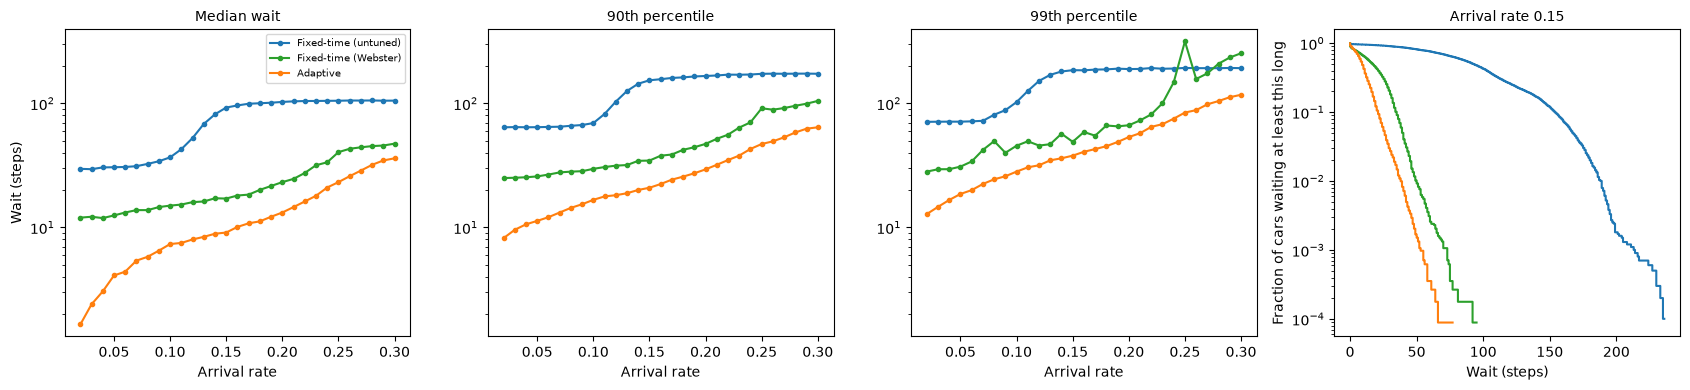

             mean_wait                wait_max                wait_p50         \
controller    adaptive  fixed webster adaptive  fixed webster adaptive  fixed   
arrival_rate                                                                    
0.05               4.9   31.3    12.8     23.9   72.3    39.5      4.1   30.6   
0.10               8.0   37.5    15.4     41.2  125.7    66.3      7.4   36.8   
0.15              10.5   92.6    17.7     56.5  211.1    71.8      9.1   92.7   
0.20              15.2  103.4    23.9    100.9  218.0   103.3     13.2  102.9   

                     wait_p90  ...         wait_p90_ew                \
controller   webster adaptive  ... webster    adaptive fixed webster   
arrival_rate                   ...                                     
0.05            12.5     11.3  ...    25.8        16.7  61.5    27.0   
0.10            15.0     16.7  ...    29.7        26.6  61.9    32.3   
0.15            17.1     20.9  ...    34.6        36.3  62.9    41.0   


In [5]:
samples = np.load(ROOT / "data" / "ext_wait_samples.npz")
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
data = means[(means["north_south_probability"] == 0.9) & (means["reaction_delay"] == 0.0)]
for ax, (value, title) in zip(axes, [("wait_p50", "Median wait"), ("wait_p90", "90th percentile"),
                                     ("wait_p99", "99th percentile")]):
    for controller in CONTROLLERS:
        runs = data[data["controller"] == controller]
        ax.plot(runs["arrival_rate"], runs[value], marker="o", markersize=3, color=COLOURS[controller],
                label=LABELS[controller])
    ax.set_yscale("log")
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("Arrival rate")
low, high = data[["wait_p50", "wait_p99"]].min().min(), data[["wait_p50", "wait_p99"]].max().max()
for ax in axes[:3]:
    ax.set_ylim(0.8 * low, 1.25 * high)     # the same range in the three percentile panels
axes[0].set_ylabel("Wait (steps)")
axes[0].legend(fontsize=7)
for controller in CONTROLLERS:
    waits = np.sort(samples[f"{controller}_0.15_0.9_0.0"])
    survival = 1 - np.arange(len(waits)) / len(waits)
    axes[3].step(waits, survival, color=COLOURS[controller], label=LABELS[controller])
axes[3].set_yscale("log")
axes[3].set_title("Arrival rate 0.15", fontsize=10)
axes[3].set_xlabel("Wait (steps)")
axes[3].set_ylabel("Fraction of cars waiting at least this long")
fig.tight_layout()
fig.savefig(FIGURES / "ext_distributions.png", dpi=200)
plt.show()

print(data[data["arrival_rate"].isin([0.05, 0.1, 0.15, 0.2])].pivot_table(
    index="arrival_rate", columns="controller",
    values=["mean_wait", "wait_p50", "wait_p90", "wait_p99", "wait_max", "wait_p90_ns", "wait_p90_ew"]).round(1))

## 4. Limited sensing

In the main experiment the adaptive controller knows the waiting time of
every car in every pocket. Here it sees only the cells nearest the stop line:
0 cells means no information at all (every green lasts the minimum 5 steps),
1 cell is a single detector at the stop line, 10 cells is the whole pocket.
Each panel is one arrival rate and north-south probability; the green line is
Webster's plan in the same conditions (from the fine sweep).

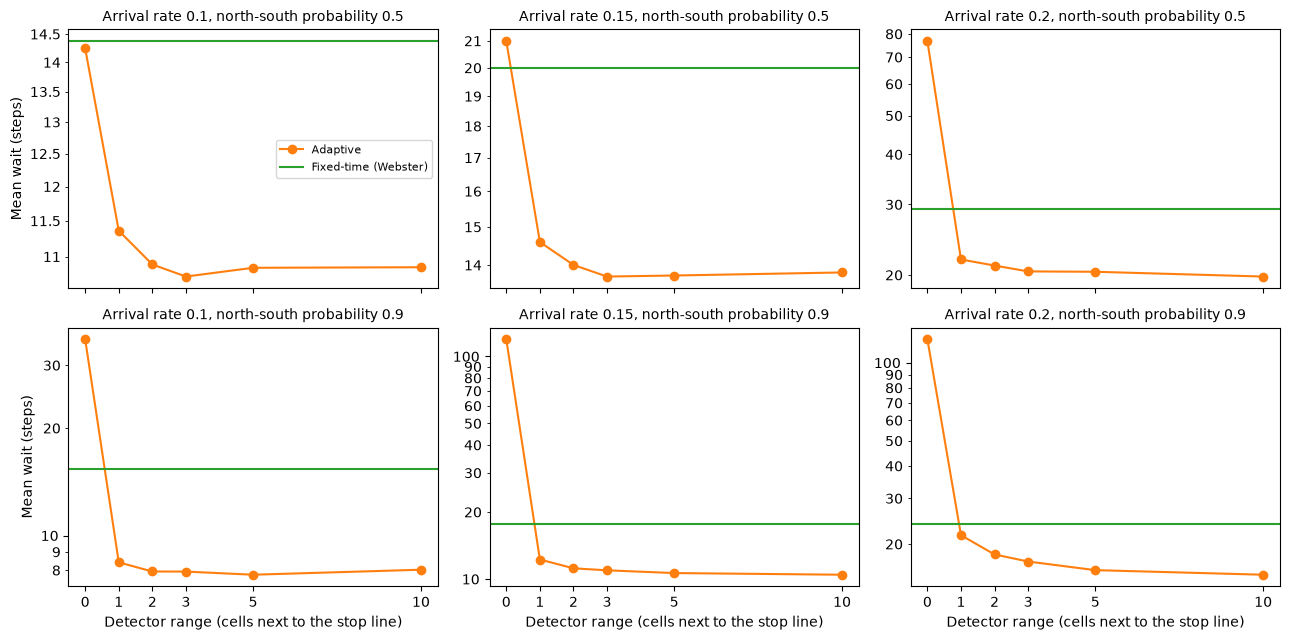

detector_range                           0     1     2     3     5     10
north_south_probability arrival_rate                                     
0.5                     0.10           14.2  11.4  10.9  10.7  10.8  10.9
                        0.15           21.0  14.6  14.0  13.7  13.7  13.8
                        0.20           76.8  21.9  21.1  20.4  20.4  19.8
0.9                     0.10           35.5   8.4   7.9   7.9   7.8   8.0
                        0.15          119.4  12.2  11.2  10.9  10.6  10.5
                        0.20          123.1  21.6  18.2  17.1  15.9  15.2


In [6]:
from matplotlib.ticker import FormatStrFormatter

sensing = pd.read_csv(ROOT / "data" / "ext_sensing.csv")
ns_values = sorted(sensing["north_south_probability"].unique())
rates = sorted(sensing["arrival_rate"].unique())
fig, axes = plt.subplots(len(ns_values), len(rates), figsize=(13, 6.5), sharex=True)
for row, p_ns in enumerate(ns_values):
    for col, rate in enumerate(rates):
        ax = axes[row, col]
        runs = sensing[(sensing["north_south_probability"] == p_ns) & (sensing["arrival_rate"] == rate)]
        mean = runs.groupby("detector_range")["mean_wait"].mean()
        ax.plot(mean.index, mean, marker="o", color=COLOURS["adaptive"], label=LABELS["adaptive"])
        webster = fine[(fine["controller"] == "webster") & (fine["north_south_probability"] == p_ns)
                       & (fine["reaction_delay"] == 0.0) & np.isclose(fine["arrival_rate"], rate)]["mean_wait"].mean()
        ax.axhline(webster, color=COLOURS["webster"], label=LABELS["webster"])
        ax.set_yscale("log")
        ax.yaxis.set_major_formatter(FormatStrFormatter("%g"))   # plain numbers on the log axis
        ax.yaxis.set_minor_formatter(FormatStrFormatter("%g"))
        ax.set_xticks(sorted(sensing["detector_range"].unique()))
        ax.set_title(f"Arrival rate {rate}, north-south probability {p_ns}", fontsize=10)
    axes[row, 0].set_ylabel("Mean wait (steps)")
for ax in axes[-1]:
    ax.set_xlabel("Detector range (cells next to the stop line)")
axes[0, 0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "ext_sensing.png", dpi=200)
plt.show()

print(sensing.pivot_table(index=["north_south_probability", "arrival_rate"], columns="detector_range",
                          values="mean_wait").round(1))

## 5. Different drivers

The main experiment gives every driver the same chance of stalling. Here the
same average delay is concentrated in fewer drivers: with slow-driver probability
0.25, a quarter of drivers stall with four times the probability and the rest
never stall. A slow driver at the front of a queue holds up everyone behind,
and the expected stalled time of a driver, $\delta/(1-\delta)$, grows faster
than $\delta$, so concentrating the delay should cost more than spreading it.
Webster's plan is still designed for the average delay.

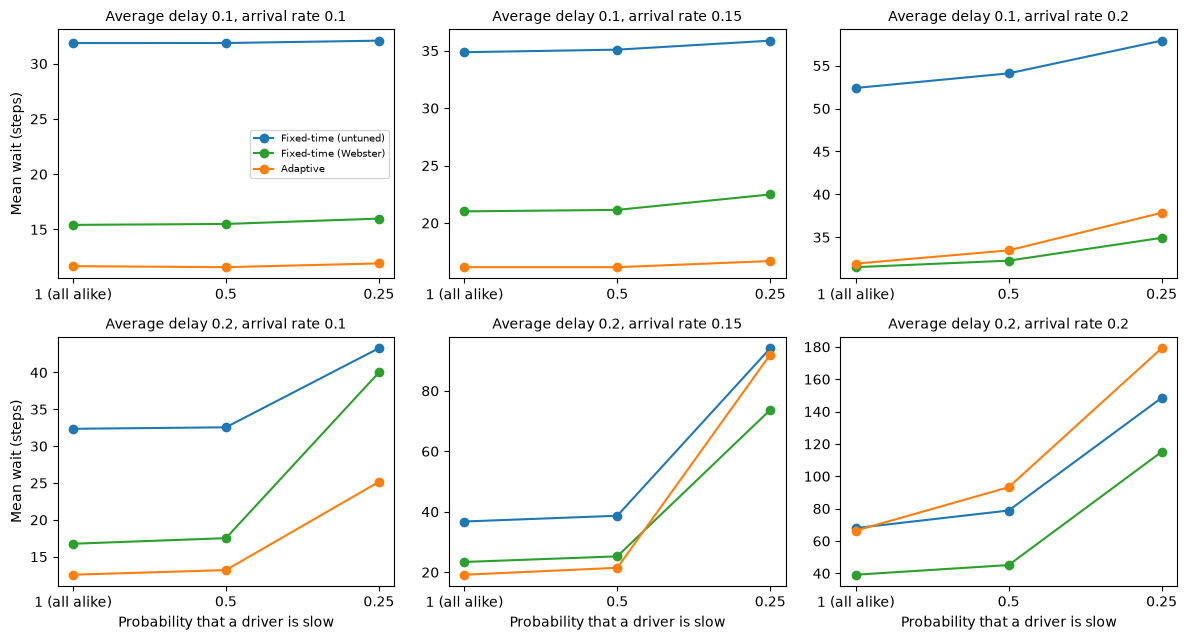

                                                    mean_wait                 \
controller                                           adaptive  fixed webster   
reaction_delay arrival_rate slow_driver_probability                            
0.1            0.10         0.25                         11.9   32.1    16.0   
                            0.50                         11.6   31.9    15.5   
                            1.00                         11.7   31.9    15.4   
               0.15         0.25                         16.7   35.9    22.5   
                            0.50                         16.2   35.1    21.1   
                            1.00                         16.2   34.9    21.0   
               0.20         0.25                         37.9   57.9    34.9   
                            0.50                         33.5   54.1    32.3   
                            1.00                         31.9   52.4    31.5   
0.2            0.10         0.25        

In [7]:
drivers = pd.read_csv(ROOT / "data" / "ext_drivers.csv")
delays = sorted(drivers["reaction_delay"].unique())
rates = sorted(drivers["arrival_rate"].unique())
slow_probabilities = [1.0, 0.5, 0.25]                     # from all drivers alike to a few very slow ones
fig, axes = plt.subplots(len(delays), len(rates), figsize=(12, 6.5))
for row, delay in enumerate(delays):
    for col, rate in enumerate(rates):
        ax = axes[row, col]
        for controller in CONTROLLERS:
            runs = drivers[(drivers["controller"] == controller) & (drivers["reaction_delay"] == delay)
                           & (drivers["arrival_rate"] == rate)]
            mean = runs.groupby("slow_driver_probability")["mean_wait"].mean()
            ax.plot(range(len(slow_probabilities)), mean[slow_probabilities], marker="o", color=COLOURS[controller],
                    label=LABELS[controller])
        ax.set_title(f"Average delay {delay}, arrival rate {rate}", fontsize=10)
        ax.set_xticks(range(len(slow_probabilities)), ["1 (all alike)", "0.5", "0.25"])
    axes[row, 0].set_ylabel("Mean wait (steps)")
for ax in axes[-1]:
    ax.set_xlabel("Probability that a driver is slow")
axes[0, 0].legend(fontsize=7)
fig.tight_layout()
fig.savefig(FIGURES / "ext_drivers.png", dpi=200)
plt.show()

print(drivers.pivot_table(index=["reaction_delay", "arrival_rate", "slow_driver_probability"],
                          columns="controller", values=["mean_wait", "stalls"]).round(1))

## 6. Time-varying demand

The arrival rate is steady at 0.1, rises linearly to 0.25 (beyond every
controller's capacity) over 500 steps, falls back over the next 500 and stays
at 0.1 while the queues clear. Webster's plan is designed for the normal
demand of 0.1, as a plan made for typical traffic would be. Curves are
averages of 20 seeds with 70% of traffic from the north and south. Left: cars
on the approaches over time (grey: arrival rate, right axis). Other panels: cars
against the current arrival rate for each controller while demand rises
(blue) and falls (red); the gap between the two is hysteresis, congestion persisting after
its cause has passed. The table also gives the extra car-steps caused by the
surge (cars above their level before it, summed over the rest of the run).

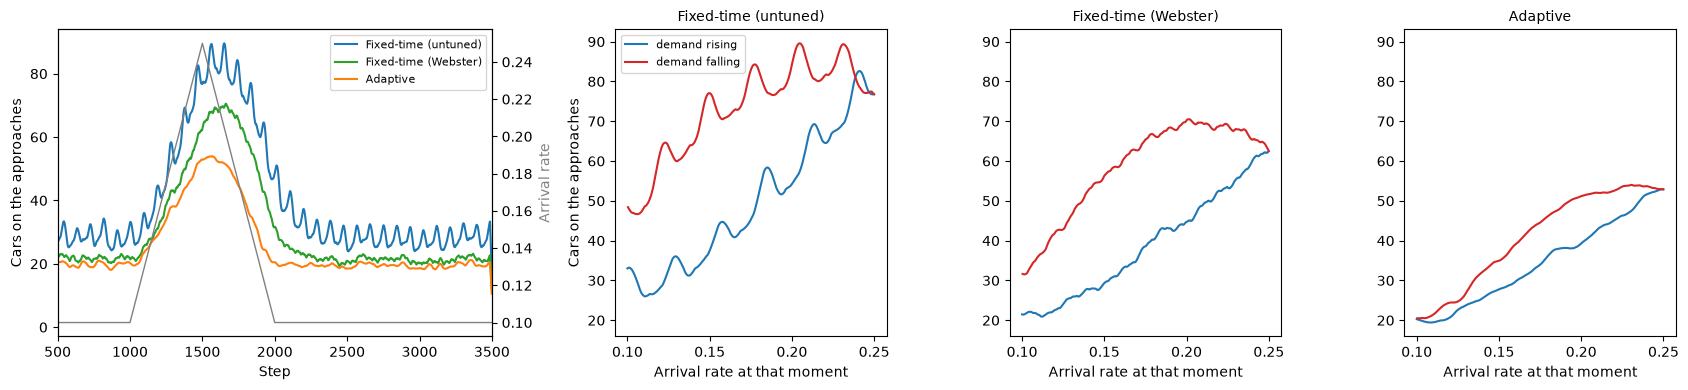

              cars before  peak cars  peak at step  \
0.5 fixed            27.8       84.0        1559.0   
    webster          21.2       65.8        1589.0   
    adaptive         19.8       59.2        1586.0   
0.7 fixed            28.4       95.6        1651.0   
    webster          21.8       73.4        1662.0   
    adaptive         19.8       54.6        1565.0   

              recovery after surge (steps)  extra car-steps  \
0.5 fixed                             26.0          27532.0   
    webster                           31.0          22068.0   
    adaptive                           0.0          19218.0   
0.7 fixed                            201.0          34928.0   
    webster                          124.0          27080.0   
    adaptive                           0.0          17545.0   

              turned away in surge  
0.5 fixed                     26.8  
    webster                   25.0  
    adaptive                  24.9  
0.7 fixed                     6

In [8]:
surge = np.load(ROOT / "data" / "ext_surge.npz")
demand = surge["demand"]
steps = np.arange(len(demand))
rise = (steps >= 1000) & (steps < 1500)
fall = (steps >= 1500) & (steps < 2000)


def smooth(x, n=25):
    return np.convolve(x, np.ones(n) / n, mode="same")


fig, axes = plt.subplots(1, 4, figsize=(17, 4), gridspec_kw={"width_ratios": [1.6, 1, 1, 1]})
for controller in CONTROLLERS:
    axes[0].plot(steps, smooth(surge[f"cars_{controller}_0.7"]), color=COLOURS[controller], label=LABELS[controller])
twin = axes[0].twinx()
twin.plot(steps, demand, color="grey", linewidth=1)
twin.set_ylabel("Arrival rate", color="grey")
axes[0].set_xlim(500, 3500)
axes[0].set_xlabel("Step")
axes[0].set_ylabel("Cars on the approaches")
axes[0].legend(fontsize=8, loc="upper right")
for ax, controller in zip(axes[1:], CONTROLLERS):
    cars = smooth(surge[f"cars_{controller}_0.7"])
    ax.plot(demand[rise], cars[rise], color="tab:blue", label="demand rising")
    ax.plot(demand[fall], cars[fall], color="tab:red", label="demand falling")
    ax.set_title(LABELS[controller], fontsize=10)
    ax.set_xlabel("Arrival rate at that moment")
for ax in axes[2:]:
    ax.sharey(axes[1])
axes[1].set_ylabel("Cars on the approaches")
axes[1].legend(fontsize=8, loc="upper left")
fig.tight_layout()
fig.savefig(FIGURES / "ext_surge.png", dpi=200)
plt.show()

# Recovery: steps after demand is back to normal (step 2000) until the 50-step
# average of cars on the road is within 10% of its level before the surge.
summary = {}
for p_ns in (0.5, 0.7):
    for controller in CONTROLLERS:
        cars = surge[f"cars_{controller}_{p_ns}"]
        before = cars[500:1000].mean()
        average = np.convolve(cars, np.ones(50) / 50, mode="valid")    # average[t] = mean of cars[t:t+50]
        back = np.flatnonzero(average[2000:] <= 1.1 * before)
        turned = surge[f"turned_away_{controller}_{p_ns}"]
        summary[(p_ns, controller)] = {
            "cars before": round(before, 1), "peak cars": round(cars.max(), 1),
            "peak at step": int(np.argmax(smooth(cars))),
            "recovery after surge (steps)": int(back[0]) if len(back) else None,
            "extra car-steps": int((cars[1000:] - before).sum()),
            "turned away in surge": round(turned[2000] - turned[1000], 1)}
print(pd.DataFrame(summary).T)

## 7. Overload: where no controller keeps up

In the main experiment, cars that find the entry full are turned away, which
caps how long anyone can wait. Here they queue off the map instead, so no car
is lost, and the arrival rate (0.1 to 0.3) and reaction delay (0 to 0.4) are
pushed past what the controllers can serve (`data/ext_overload.csv`;
north-south probability 0.5 and 0.8, turning probabilities 0.2, 10 seeds).
The same runs are repeated with blocked cars turned away, for comparison.

A controller **keeps up** if it serves at least 95% of the arriving cars;
otherwise its queue grows for the whole run and every later car waits longer.
Left: the best of the three controllers' mean wait, with cells where no
controller keeps up outlined in black. Right: mean wait against arrival rate
for each controller with reaction delay 0.3, when blocked cars queue (blue,
green, orange) and when they are turned away (purple, brown, red). Waits count only cars that reached the
junction by the end of the run, so in overload the true waits are even longer.

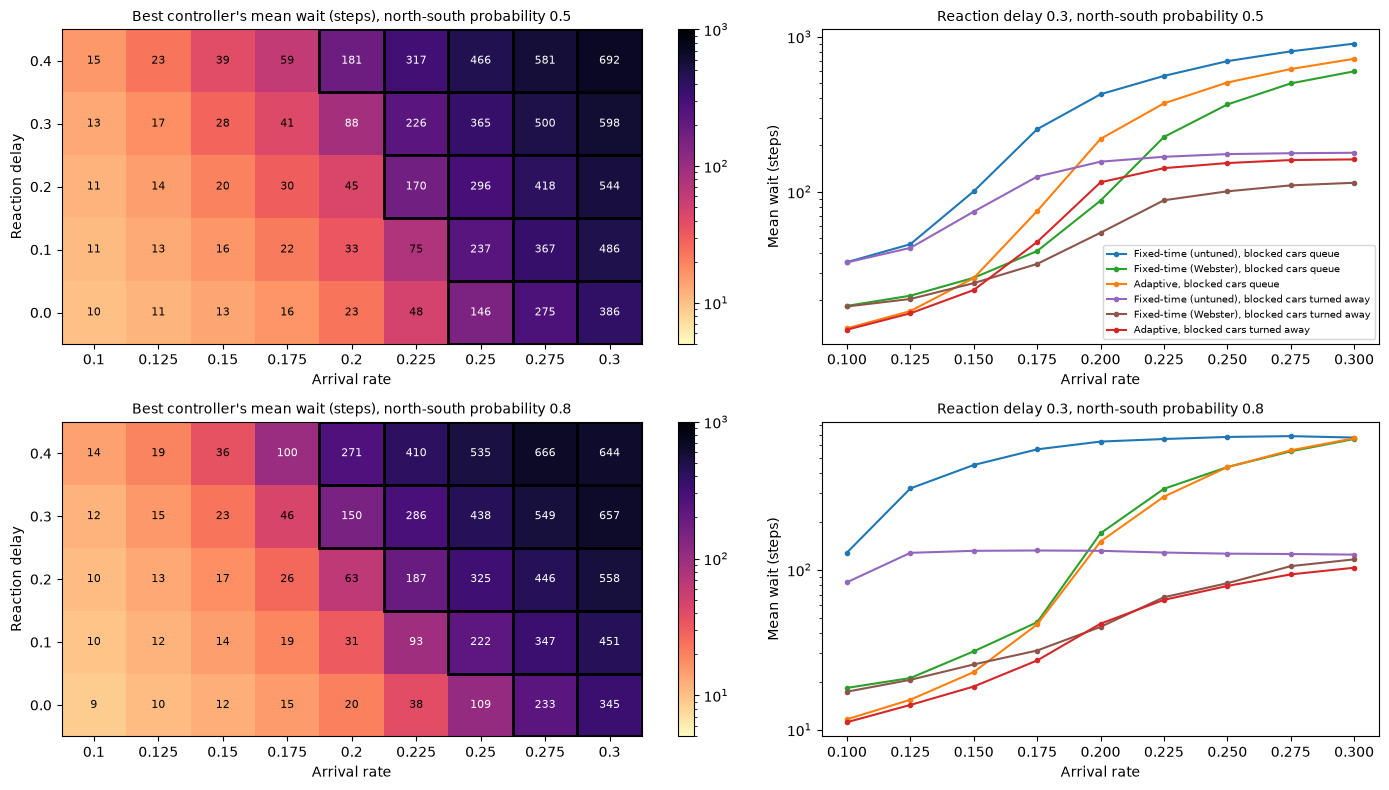

Lowest arrival rate at which no controller serves 95% of arrivals (NaN = all keep up to 0.3)
north_south_probability    0.5    0.8
reaction_delay                       
0.0                      0.250  0.275
0.1                      0.250  0.250
0.2                      0.225  0.225
0.3                      0.225  0.200
0.4                      0.200  0.200

Mean wait with blocked cars queuing vs turned away, arrival rate 0.3, reaction delay 0.3
                                    mean_wait  wait_turned_away  served
north_south_probability controller                                     
0.5                     adaptive       720.09            161.65    0.59
                        fixed          901.91            178.37    0.52
                        webster        597.84            114.24    0.67
0.8                     adaptive       663.50            102.95    0.62
                        fixed          670.25            124.36    0.46
                        webster        656.91  

In [9]:
from matplotlib.colors import LogNorm
from matplotlib.patches import Rectangle

overload = pd.read_csv(ROOT / "data" / "ext_overload.csv")
overload["served"] = overload["throughput"] / (400 * overload["arrival_rate"])   # fraction of arrivals served
queued = overload[overload["queue_blocked_arrivals"]]
removed = overload[~overload["queue_blocked_arrivals"]]
SETTING = ["north_south_probability", "reaction_delay", "arrival_rate"]
per_controller = queued.groupby(SETTING + ["controller"])[["mean_wait", "served"]].mean().reset_index()
best = per_controller.groupby(SETTING).agg(best_wait=("mean_wait", "min"), best_served=("served", "max")).reset_index()

ns_values = sorted(queued["north_south_probability"].unique())
fig, axes = plt.subplots(2, 2, figsize=(14, 8), gridspec_kw={"width_ratios": [1.3, 1]})
for row, p_ns in enumerate(ns_values):
    ax = axes[row, 0]
    grid = best[best["north_south_probability"] == p_ns]
    waits = grid.pivot(index="reaction_delay", columns="arrival_rate", values="best_wait")
    served = grid.pivot(index="reaction_delay", columns="arrival_rate", values="best_served")
    image = ax.imshow(waits.values, cmap="magma_r", norm=LogNorm(5, 1000), origin="lower", aspect="auto")
    for i in range(waits.shape[0]):
        for j in range(waits.shape[1]):
            ax.text(j, i, f"{waits.values[i, j]:.0f}", ha="center", va="center", fontsize=8,
                    color="white" if waits.values[i, j] > 80 else "black")
            if served.values[i, j] < 0.95:                     # no controller keeps up here
                ax.add_patch(Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, edgecolor="black", linewidth=2))
    ax.set_xticks(range(waits.shape[1]), waits.columns)
    ax.set_yticks(range(waits.shape[0]), waits.index)
    ax.set_xlabel("Arrival rate")
    ax.set_ylabel("Reaction delay")
    ax.set_title(f"Best controller's mean wait (steps), north-south probability {p_ns}", fontsize=10)
    fig.colorbar(image, ax=ax)

    ax = axes[row, 1]
    for data, colours, how in [(queued, COLOURS, "queue"), (removed, ALT_COLOURS, "turned away")]:
        runs = data[(data["north_south_probability"] == p_ns) & (data["reaction_delay"] == 0.3)]
        for controller in CONTROLLERS:
            mean = runs[runs["controller"] == controller].groupby("arrival_rate")["mean_wait"].mean()
            ax.plot(mean.index, mean, marker="o", markersize=3, color=colours[controller],
                    label=f"{LABELS[controller]}, blocked cars {how}")
    ax.set_yscale("log")
    ax.set_xlabel("Arrival rate")
    ax.set_ylabel("Mean wait (steps)")
    ax.set_title(f"Reaction delay 0.3, north-south probability {p_ns}", fontsize=10)
axes[0, 1].legend(fontsize=7)
fig.tight_layout()
fig.savefig(FIGURES / "ext_overload.png", dpi=200)
plt.show()

# The lowest arrival rate at which no controller keeps up, for each setting.
failing = best[best["best_served"] < 0.95]
onset = failing.groupby(["north_south_probability", "reaction_delay"])["arrival_rate"].min().unstack(0)
print("Lowest arrival rate at which no controller serves 95% of arrivals (NaN = all keep up to 0.3)")
print(onset.reindex(sorted(queued["reaction_delay"].unique())))

worst = per_controller.merge(
    removed.groupby(SETTING + ["controller"])["mean_wait"].mean().rename("wait_turned_away").reset_index())
print("\nMean wait with blocked cars queuing vs turned away, arrival rate 0.3, reaction delay 0.3")
print(worst[(worst["arrival_rate"] == 0.3) & (worst["reaction_delay"] == 0.3)]
      .set_index(["north_south_probability", "controller"])[["mean_wait", "wait_turned_away", "served"]].round(2))

### The one-setting sweeps with blocked cars kept in a queue

The baseline and the one-setting sweeps of `notebooks/Results.ipynb` (arrival rate 0.15,
balanced, turning probabilities 0.2, no reaction delay, changing one setting at
a time) repeated with blocked cars waiting in a queue off the map instead of
being turned away (`python -m utils.results_sweeps --queued`,
`data/fine_sweeps_queued.csv`). Blue, green and orange: blocked cars queue;
purple, brown and red: blocked cars turned away. Waits are on a log scale. The
last panel shows how many cars, on average, are waiting off the map: once a
controller cannot keep up, this queue grows for the whole run.

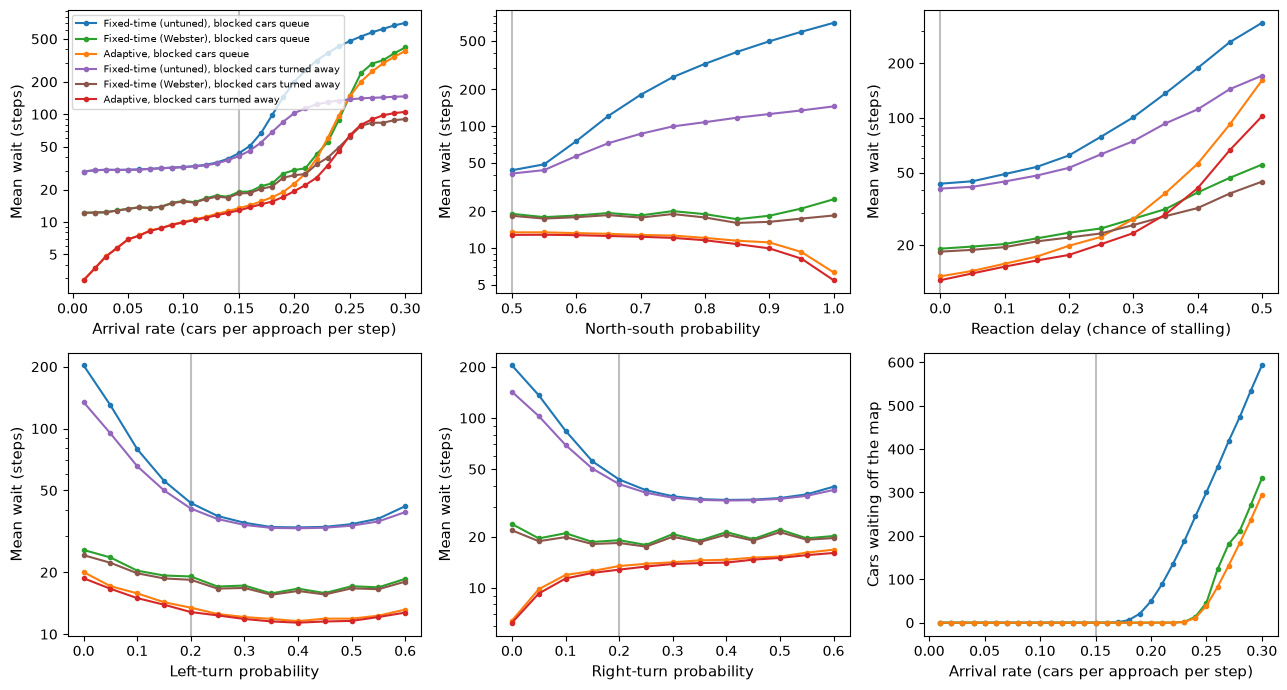

Baseline mean wait (steps)
            queue  turned away
controller                    
fixed        42.3         39.8
webster      19.0         18.4
adaptive     13.5         13.0

Mean wait (steps) against arrival rate
              queue                  turned away                 
controller    fixed webster adaptive       fixed webster adaptive
arrival_rate                                                     
0.15           43.5    19.1     13.4        40.8    18.4     12.8
0.20          200.0    30.3     22.7       102.6    27.2     19.3
0.22          314.6    42.4     38.5       123.5    34.3     25.7
0.25          477.4   148.1    146.2       137.4    62.1     63.7
0.30          705.0   416.6    386.4       146.6    90.2    105.2

Mean wait (steps) against reaction delay
                queue                  turned away                 
controller      fixed webster adaptive       fixed webster adaptive
reaction_delay                                                     
0.2 

In [10]:
import sys

from matplotlib.ticker import FormatStrFormatter, LogLocator, NullFormatter

sys.path.insert(0, str(ROOT.resolve()))        # so that utils/ can be imported
from utils.results_sweeps import BASELINE

FACTORS = {
    "demand": ("arrival_rate", "Arrival rate (cars per approach per step)"),
    "ns_probability": ("north_south_probability", "North-south probability"),
    "reaction_delay": ("reaction_delay", "Reaction delay (chance of stalling)"),
    "left_probability": ("left_turn_probability", "Left-turn probability"),
    "right_probability": ("right_turn_probability", "Right-turn probability"),
}
turned_away = pd.read_csv(ROOT / "data" / "fine_sweeps.csv")
queued = pd.read_csv(ROOT / "data" / "fine_sweeps_queued.csv")

panels = [("demand", "mean_wait"), ("ns_probability", "mean_wait"), ("reaction_delay", "mean_wait"),
          ("left_probability", "mean_wait"), ("right_probability", "mean_wait"), ("demand", "queue_outside")]
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, (factor, value) in zip(axes.flat, panels):
    column, label = FACTORS[factor]
    modes = [(queued, COLOURS, "queue")] + ([(turned_away, ALT_COLOURS, "turned away")] if value == "mean_wait" else [])
    for data, colours, how in modes:
        runs = data[data["sweep"] == factor]
        for controller in CONTROLLERS:
            mean = runs[runs["controller"] == controller].groupby(column)[value].mean()
            ax.plot(mean.index, mean, marker="o", markersize=3, color=colours[controller],
                    label=f"{LABELS[controller]}, blocked cars {how}")
    ax.axvline(BASELINE[factor], color="0.75", linewidth=1.5, zorder=0)
    ax.set_xlabel(label, fontsize=11)
    if value == "mean_wait":
        ax.set_yscale("log")
        ax.yaxis.set_major_locator(LogLocator(base=10, subs=(1, 2, 5)))   # ticks at 1, 2, 5, 10, 20, 50, ...
        ax.yaxis.set_major_formatter(FormatStrFormatter("%g"))
        ax.yaxis.set_minor_formatter(NullFormatter())
        ax.set_ylabel("Mean wait (steps)", fontsize=11)
    else:
        ax.set_ylabel("Cars waiting off the map", fontsize=11)
axes[0, 0].legend(fontsize=7)
fig.tight_layout()
fig.savefig(FIGURES / "ext_queued.png", dpi=200)
plt.show()


def waits(data, factor, values):
    # Mean wait of each controller at the chosen values of one setting.
    column = FACTORS[factor][0]
    runs = data[(data["sweep"] == factor) & data[column].isin(values)]
    return runs.pivot_table(index=column, columns="controller", values="mean_wait")[CONTROLLERS]


both = lambda factor, values: pd.concat({"queue": waits(queued, factor, values),
                                         "turned away": waits(turned_away, factor, values)}, axis=1).round(1)
baseline = pd.DataFrame({"queue": queued[queued["sweep"] == "baseline"].groupby("controller")["mean_wait"].mean(),
                         "turned away": turned_away[turned_away["sweep"] == "baseline"]
                         .groupby("controller")["mean_wait"].mean()}).loc[CONTROLLERS]
print("Baseline mean wait (steps)")
print(baseline.round(1))
print("\nMean wait (steps) against arrival rate")
print(both("demand", [0.15, 0.2, 0.22, 0.25, 0.3]))
print("\nMean wait (steps) against reaction delay")
print(both("reaction_delay", [0.2, 0.3, 0.4, 0.5]))
served = queued[queued["sweep"] == "demand"].assign(served=lambda d: d["throughput"] / (400 * d["arrival_rate"]))
print("\nFraction of arriving cars served when they queue, against arrival rate")
print(served.pivot_table(index="arrival_rate", columns="controller", values="served")
      .loc[[0.2, 0.22, 0.24, 0.26, 0.28, 0.3], CONTROLLERS].round(2))